# WasteSort — Day 2: Tuesday dataset preparation
**Goal Diggers · BCS34**

Expected output: a dataset inventory and a preprocessing notebook ready for training.

This notebook loads image paths and labels in Pandas, inspects formats and duplicates, records label encoding, demonstrates resizing and preserves the fixed data partitions. It **does not train a classifier**.

In Google Colab, select **Runtime → Run all**. A CPU runtime is sufficient. Installation and the first dataset download require internet access. Each run uses a new folder and leaves published results unchanged. Review the outputs and download the export at the end.

The included executed copy was run locally on Windows; a Colab execution is not yet verified.

In [1]:
from pathlib import Path
import os, sys, subprocess, tempfile, shutil, json, hashlib

workspace = Path(tempfile.mkdtemp(prefix="wastesort-day2-"))
source = workspace / "source"
subprocess.run(["git", "clone", "--quiet", "https://github.com/haerinfan/wastesort.git", str(source)], check=True)
# Pin the implementation used for the prepared Day 2 lesson.
subprocess.run(["git", "-C", str(source), "checkout", "--quiet", "97d22b3"], check=True)
source_commit = subprocess.check_output(["git", "-C", str(source), "rev-parse", "HEAD"], text=True).strip()
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(source / "requirements.txt")], check=True)
print("Implementation commit:", source_commit)
print("A new experiment folder has been created.")

Implementation commit: 97d22b32d1a09fc7c309804a4d595776cad8c4a7
A new experiment folder has been created.


## 1. Download the documented source and prepare a fresh copy
We use only the creators' resized TrashNet archive. The archive checksum and published split are copied from the repository, so a changed download or changed partition stops the run.

Paths identify files; folder names supply the target labels. No personal data or campus-photo collection is required for this exercise.

In [2]:
run = workspace / "preparation"
(run / "data").mkdir(parents=True)
(run / "reports").mkdir()
for relative in ["protocol.json", "data/provenance.json", "data/splits.csv", "reports/data_audit.json"]:
    shutil.copyfile(source / relative, run / relative)
env = dict(os.environ, WASTESORT_ROOT=str(run))
def execute(module):
    result = subprocess.run([sys.executable, "-u", "-m", "wastesort." + module],
                            cwd=source, env=env, check=True, capture_output=True, text=True)
    print(result.stdout)
execute("data")
execute("preparation")

split      test  train  validation
label                             
cardboard    59    287          57
glass        73    352          73
metal        63    281          65
paper        93    411          90
plastic      70    343          67
trash        18    100          19
Prepared 2521 images; 45 candidate pairs; manifest 251874bb101118f346a20489163b4b455d79d690a4b404b6aafd51471d5d3f16



Day 2 inventory: 2527 source images; 2521 included.
included   False  True 
label                  
cardboard      0    403
glass          3    498
metal          1    409
paper          0    594
plastic        2    480
trash          0    137



## 2. Load paths, labels and image properties in Pandas
The inventory includes **all source files**, including excluded files and their reasons. The training manifest includes only usable images.

`label_id` is a category code, not a ranking or measured quantity.

In [3]:
import pandas as pd
import numpy as np
from PIL import Image, ImageOps
from IPython.display import display

inventory = pd.read_csv(run / "reports/dataset_inventory.csv").fillna("")
manifest = pd.read_csv(run / "data/splits.csv")
encoding = json.loads((run / "reports/label_encoding.json").read_text())
display(inventory[["path", "label", "label_id", "format", "mode", "width", "height", "included", "split"]].head(12))
display(pd.DataFrame({"label": list(encoding), "label_id": list(encoding.values())}))
assert inventory.path.is_unique
assert set(manifest.label) == set(encoding)
print("Inventory rows:", len(inventory), "| usable rows:", len(manifest))

,path,label,label_id,format,mode,width,height,included,split
0,data/raw/cardboard/cardboard1.jpg,cardboard,0,JPEG,RGB,512,384,True,train
1,data/raw/cardboard/cardboard10.jpg,cardboard,0,JPEG,RGB,512,384,True,train
2,data/raw/cardboard/cardboard100.jpg,cardboard,0,JPEG,RGB,512,384,True,train
3,data/raw/cardboard/cardboard101.jpg,cardboard,0,JPEG,RGB,512,384,True,train
4,data/raw/cardboard/cardboard102.jpg,cardboard,0,JPEG,RGB,512,384,True,train
5,data/raw/cardboard/cardboard103.jpg,cardboard,0,JPEG,RGB,512,384,True,train
6,data/raw/cardboard/cardboard104.jpg,cardboard,0,JPEG,RGB,512,384,True,train
7,data/raw/cardboard/cardboard105.jpg,cardboard,0,JPEG,RGB,512,384,True,train
8,data/raw/cardboard/cardboard106.jpg,cardboard,0,JPEG,RGB,512,384,True,train
9,data/raw/cardboard/cardboard107.jpg,cardboard,0,JPEG,RGB,512,384,True,train


,label,label_id
0,cardboard,0
1,glass,1
2,metal,2
3,paper,3
4,plastic,4
5,trash,5


Inventory rows: 2527 | usable rows: 2521


## 3. Count classes and inspect formats
Class counts matter because a model can perform well on common materials while missing a small category. Trash is the smallest class. All source images in this audit are readable RGB JPEGs, sized 512 × 384 pixels.

,original,usable,excluded
label,,,
cardboard,403,403,0
glass,501,498,3
metal,410,409,1
paper,594,594,0
plastic,482,480,2
trash,137,137,0


,format,mode,width,height,images
0,JPEG,RGB,512,384,2527


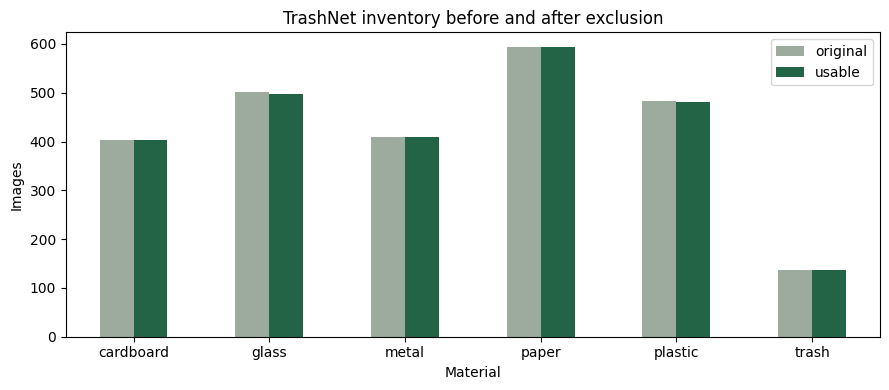

In [4]:
counts = inventory.groupby("label").agg(original=("path", "size"), usable=("included", "sum")).reindex(encoding)
counts["excluded"] = counts.original - counts.usable
display(counts)
display(inventory.groupby(["format", "mode", "width", "height"]).size().reset_index(name="images"))
import matplotlib.pyplot as plt
ax = counts[["original", "usable"]].plot.bar(figsize=(9, 4), color=["#9CAB9E", "#236447"])
ax.set(title="TrashNet inventory before and after exclusion", xlabel="Material", ylabel="Images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. Inspect duplicate findings
Byte hashes detect identical files. Decoded-pixel hashes also detect identical image content saved with different file encodings. The audit found three identical-pixel pairs with conflicting material labels. It excluded **all six copies** rather than guessing the correct label.

Perceptual hashes identify possible near-duplicates; they are a screening tool, not proof of the same object. The 45 candidate pairs are connected into groups and kept in the same partition. Human review is still pending.

,path,reason,retained
0,data/raw/glass/glass115.jpg,conflicting_labels_for_identical_pixels,
1,data/raw/metal/metal91.jpg,conflicting_labels_for_identical_pixels,
2,data/raw/glass/glass176.jpg,conflicting_labels_for_identical_pixels,
3,data/raw/plastic/plastic152.jpg,conflicting_labels_for_identical_pixels,
4,data/raw/glass/glass389.jpg,conflicting_labels_for_identical_pixels,
5,data/raw/plastic/plastic332.jpg,conflicting_labels_for_identical_pixels,


,left,right,hamming_distance,same_label
0,data/raw/cardboard/cardboard15.jpg,data/raw/cardboard/cardboard361.jpg,2,True
1,data/raw/cardboard/cardboard386.jpg,data/raw/cardboard/cardboard72.jpg,2,True
2,data/raw/metal/metal165.jpg,data/raw/metal/metal166.jpg,6,True
3,data/raw/metal/metal11.jpg,data/raw/metal/metal221.jpg,6,True
4,data/raw/metal/metal120.jpg,data/raw/metal/metal50.jpg,4,True
5,data/raw/metal/metal122.jpg,data/raw/metal/metal57.jpg,6,True
6,data/raw/metal/metal155.jpg,data/raw/metal/metal6.jpg,2,True
7,data/raw/metal/metal394.jpg,data/raw/metal/metal76.jpg,6,True
8,data/raw/metal/metal149.jpg,data/raw/metal/metal9.jpg,6,True
9,data/raw/paper/paper101.jpg,data/raw/paper/paper108.jpg,0,True


Excluded: 6 | near-duplicate candidate pairs: 45


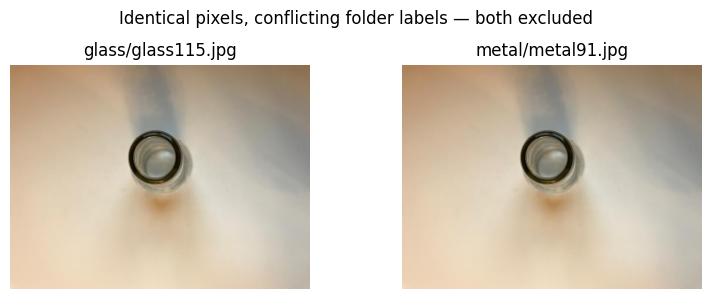

In [5]:
excluded = pd.read_csv(run / "reports/excluded.csv").fillna("")
pairs = pd.read_csv(run / "reports/near_duplicate_candidates.csv")
display(excluded)
display(pairs.head(10))
print("Excluded:", len(excluded), "| near-duplicate candidate pairs:", len(pairs))

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for ax, relative in zip(axes, ["data/raw/glass/glass115.jpg", "data/raw/metal/metal91.jpg"]):
    with Image.open(run / relative) as im:
        ax.imshow(im)
    ax.set_title(relative.split("/raw/")[1])
    ax.axis("off")
plt.suptitle("Identical pixels, conflicting folder labels — both excluded")
plt.tight_layout()
plt.show()

## 5. Verify the fixed split before transformations
Training data fits the model. Validation data supports model and setting selection. Test data stays reserved until the final choice is frozen.

The published partition contains 1,774 training, 371 validation and 376 test images. The proportions are approximately 70/15/15; group preservation means exact percentages are unnecessary. This notebook checks separation but does not train on or tune against test images.

In [6]:
display(pd.crosstab(manifest.label, manifest.split).reindex(encoding))
assert manifest.path.is_unique
assert manifest.groupby("group").split.nunique().max() == 1
assert manifest.groupby("pixel_sha256").split.nunique().max() == 1
for split in ["train", "validation", "test"]:
    assert set(manifest[manifest.split == split].label) == set(encoding)
published_sha = json.loads((source / "reports/data_audit.json").read_text())["manifest_sha256"]
observed_sha = hashlib.sha256((run / "data/splits.csv").read_bytes()).hexdigest()
assert observed_sha == published_sha
print("No recorded image or candidate group crosses partitions.")
print("Published manifest checksum preserved:", observed_sha)

split,test,train,validation
label,,,
cardboard,59,287,57
glass,73,352,73
metal,63,281,65
paper,93,411,90
plastic,70,343,67
trash,18,100,19


No recorded image or candidate group crosses partitions.
Published manifest checksum preserved: 251874bb101118f346a20489163b4b455d79d690a4b404b6aafd51471d5d3f16


## 6. Demonstrate resizing and label encoding on training images
Classical models use 64 × 64 grayscale inputs to calculate 1,764 HOG features. Neural models use 160 × 160 RGB inputs. The small CNN receives values in [0, 1]; MobileNetV2 additionally applies the pretrained model's mean and standard deviation.

The square resize standardizes input shape and changes the original aspect ratio. It is the documented baseline, not a claim that this resize is optimal. Random augmentation belongs only in training; validation and test processing stays deterministic.

HOG batch: (8, 1764)
CNN batch: (8, 3, 160, 160)
MobileNetV2 batch: (8, 3, 160, 160)
Encoded labels: [0, 0, 0, 0, 0, 0, 0, 0]


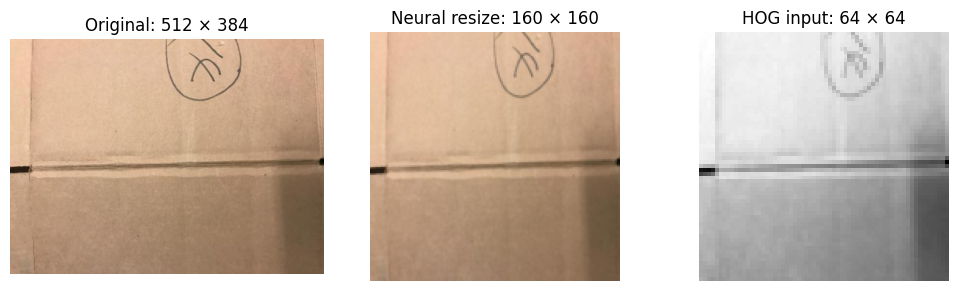

In [7]:
sys.path.insert(0, str(source))
from wastesort.models import hog_features, transforms_for

training = manifest[manifest.split == "train"].head(8)
images = []
for relative in training.path:
    with Image.open(run / relative) as im:
        images.append(ImageOps.exif_transpose(im).convert("RGB"))
label_ids = training.label.map(encoding).to_numpy(dtype=np.int64)
hog_batch = np.stack([hog_features(im) for im in images])
cnn_batch = np.stack([transforms_for("cnn")(im).numpy() for im in images])
mobile_batch = np.stack([transforms_for("mobilenet")(im).numpy() for im in images])
assert hog_batch.shape == (8, 1764)
assert cnn_batch.shape == mobile_batch.shape == (8, 3, 160, 160)
assert 0 <= cnn_batch.min() <= cnn_batch.max() <= 1
print("HOG batch:", hog_batch.shape)
print("CNN batch:", cnn_batch.shape)
print("MobileNetV2 batch:", mobile_batch.shape)
print("Encoded labels:", label_ids.tolist())

fig, axes = plt.subplots(1, 3, figsize=(10, 3))
views = [images[0], images[0].resize((160,160), Image.Resampling.BILINEAR),
         images[0].convert("L").resize((64,64), Image.Resampling.BILINEAR)]
for ax, im, title in zip(axes, views, ["Original: 512 × 384", "Neural resize: 160 × 160", "HOG input: 64 × 64"]):
    ax.imshow(im, cmap="gray" if im.mode == "L" else None)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 7. Export the Tuesday evidence
The ZIP includes the full inventory, usable-image manifest, exclusions, split counts, encoding, preprocessing plan, a review worksheet and the local visual inventory. Raw images are downloaded on demand and are not redistributed in this export.

The worksheet has blank reviewer/decision fields intentionally. Automated preparation does not certify that a member has reviewed every image or completed the presentation.

In [8]:
export = workspace / "day2-export"
export.mkdir()
files = ["data/splits.csv", "data/provenance.json", "reports/data_audit.json",
         "reports/dataset_inventory.csv", "reports/excluded.csv",
         "reports/near_duplicate_candidates.csv", "reports/split_counts.csv",
         "reports/label_encoding.json", "reports/preprocessing.json",
         "reports/manual_review_worksheet.csv", "reports/audit_images/inventory.html"]
for relative in files:
    dest = export / relative
    dest.parent.mkdir(parents=True, exist_ok=True)
    shutil.copyfile(run / relative, dest)
(export / "source_commit.txt").write_text(source_commit)
archive = shutil.make_archive(str(workspace / "WasteSort_Day2_Outputs"), "zip", export)
print("Day 2 export created: WasteSort_Day2_Outputs.zip")
if "google.colab" in sys.modules:
    from google.colab import files
    files.download(archive)
else:
    from IPython.display import FileLink
    display(FileLink(archive))

Day 2 export created: WasteSort_Day2_Outputs.zip


C:\Users\Administrator\Documents\Codex\2026-10-20\files-mentioned-by-the-user-wastesort\work\tuesday-execution\wastesort-day2-vsrhiyyt\WasteSort_Day2_Outputs.zip

## Explain the work

1. Why does every image need a label?
2. Why were all six conflicting duplicates excluded?
3. Why must candidate duplicates stay in the same partition?
4. Why are encoded labels still categories?
5. Why do different model families require different input transformations?

Sources: [TrashNet](https://github.com/garythung/trashnet), [the creators' dataset host](https://huggingface.co/datasets/garythung/trashnet), the supplied weekly plan and the project's recorded audit/protocol.

AI assisted preparation and execution. Goal Diggers must verify, explain and record genuine member contributions.